In [14]:
# Import required libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
# Load Past Data
past_data = pd.read_csv('../../data/vsf_ml_models/data/indexes_past_data.csv', dayfirst=True)
print("Past Data:")
print(past_data.head())

# Load Future Data
future_data = pd.read_csv('../../data/vsf_ml_models/data/indexes_future_data.csv', dayfirst=True)
print("\nFuture Data:")
print(future_data.head())


In [16]:
# Convert Date to datetime format
past_data['Date'] = pd.to_datetime(past_data['Date'], dayfirst=True)
future_data['Date'] = pd.to_datetime(future_data['Date'], dayfirst=True)

# Sort data by date
past_data = past_data.sort_values(by='Date')
future_data = future_data.sort_values(by='Date')


In [ ]:
# Add Circulating Supply (CS) for future data (quarterly targets)
quarterly_cs = {
    '2025-03-31': 1.695 * 1e9,  # Q1 2025
    '2025-06-30': 1.695 * 1e9,  # Q2 2025
    '2025-09-30': 1.695 * 1e9,  # Q3 2025
    '2025-12-31': 1.695 * 1e9   # Q4 2025
}

# Map quarterly CS to future data
future_data['CS'] = future_data['Date'].dt.to_period('Q').map(quarterly_cs)

# Fill any missing CS values with 0 to avoid NaN
future_data['CS'] = future_data['CS'].fillna(0)

# Calculate VS as 9% of CS
future_data['VS'] = future_data['CS'] * 0.09

print("\nFuture Data with CS and VS:")
print(future_data.head())


In [ ]:
# Calculate VS for past data
past_data['VS'] = past_data['CS'] * past_data['PR']

print("\nUpdated Past Data with VS:")
print(past_data.head())


In [21]:
# Define features and target
features = ['AVPI', 'LAR', 'OP_Price', 'PR', 'PSI', 'VPI', 'CS']
target = 'VS'

X = past_data[features]
y = past_data[target]

print("\nFeatures:")
print(X.head())
print("\nTarget (VS):")
print(y.head())



Features:
       AVPI       LAR  OP_Price        PR  PSI       VPI         CS
0  0.000833  0.093632  1.719741  0.090822  0.0  0.970289  911294948
1  0.000369  0.330732  1.790326  0.090529  0.0  0.428071  911294948
2  0.000374  0.202520  1.800778  0.091018  0.0  0.436652  911294948
3  0.000380  0.196524  1.712827  0.090122  0.0  0.438521  911294948
4  0.000286  0.542970  2.178050  0.090156  0.0  0.330085  911294948

Target (VS):
0    8.276557e+07
1    8.249845e+07
2    8.294435e+07
3    8.212736e+07
4    8.215848e+07
Name: VS, dtype: float64


In [22]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training Data Shape: {X_train.shape}")
print(f"Testing Data Shape: {X_test.shape}")


Training Data Shape: (290, 7)
Testing Data Shape: (73, 7)


In [23]:
# Initialize the Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=200, random_state=42)

# Train the model
rf_model.fit(X_train, y_train)

# Predict on the test set
y_pred = rf_model.predict(X_test)



Model Performance:
Mean Absolute Error (MAE): 176716.70
Root Mean Squared Error (RMSE): 411908.70
R² Score: 1.00


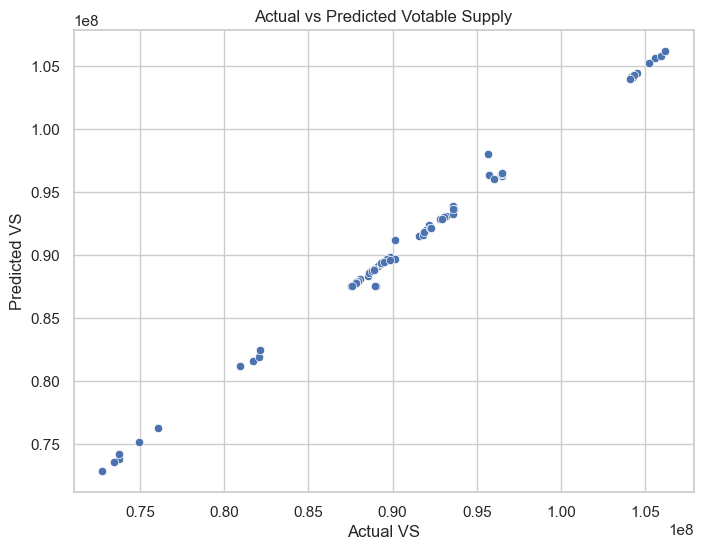

In [24]:
# Evaluate Model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nModel Performance:")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.2f}")

# Plot Actual vs Predicted VS
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred)
plt.xlabel("Actual VS")
plt.ylabel("Predicted VS")
plt.title("Actual vs Predicted Votable Supply")
plt.show()


In [25]:
# Predict Ideal Votable Supply for future data
X_future = future_data[features]
future_data['Predicted_VS'] = rf_model.predict(X_future)

# Display future predictions
print("\nFuture Quarterly Predictions for Ideal Votable Supply:")
print(future_data[['Date', 'CS', 'Predicted_VS']])

# Save predictions to a CSV file
future_data.to_csv('Future_Quarterly_VS_Predictions.csv', index=False)



Future Quarterly Predictions for Ideal Votable Supply:
          Date   CS  Predicted_VS
0   2024-12-01  0.0  7.516559e+07
1   2024-12-02  0.0  7.513023e+07
2   2024-12-03  0.0  7.575497e+07
3   2024-12-04  0.0  7.511650e+07
4   2024-12-05  0.0  7.512956e+07
..         ...  ...           ...
391 2025-12-27  0.0  7.512903e+07
392 2025-12-28  0.0  7.512903e+07
393 2025-12-29  0.0  7.512903e+07
394 2025-12-30  0.0  7.512903e+07
395 2025-12-31  0.0  7.512903e+07

[396 rows x 3 columns]
